In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import prophet
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

c:\ProgramData\anaconda3\envs\datascience\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
dir(Prophet)

['__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_load_stan_backend',
 '_logistic_uncertainty',
 '_make_historical_mat_time',
 '_make_trend_shift_matrix',
 '_sample_uncertainty',
 'add_country_holidays',
 'add_group_component',
 'add_regressor',
 'add_seasonality',
 'calculate_initial_params',
 'construct_holiday_dataframe',
 'fit',
 'flat_growth_init',
 'flat_trend',
 'fourier_series',
 'initialize_scales',
 'linear_growth_init',
 'logistic_growth_init',
 'make_all_seasonality_features',
 'make_future_dataframe',
 'make_holiday_features',
 'make_seasonality_features',
 'parse_seasonalit

In [4]:
df=pd.read_csv('DATASETS/new_dataset.csv', parse_dates=['date'])
df.set_index('date', inplace=True)
df.head()

,price,exchange rate (1 USD TO TZS),observation
date,,,
2010-01-01,1533.9349,1313.0056,baseline / no prior month
2010-02-01,1620.3256,1323.5843,normal month-over-month move
2010-03-01,1572.1865,1326.3845,normal month-over-month move
2010-04-01,1681.5984,1330.0796,normal month-over-month move
2010-05-01,1711.4398,1343.2834,normal month-over-month move


In [5]:
print(df.index)

DatetimeIndex(['2010-01-01', '2010-02-01', '2010-03-01', '2010-04-01',
               '2010-05-01', '2010-06-01', '2010-07-01', '2010-08-01',
               '2010-09-01', '2010-10-01',
               ...
               '2025-03-01', '2025-04-01', '2025-05-01', '2025-06-01',
               '2025-07-01', '2025-08-01', '2025-09-01', '2025-10-01',
               '2025-11-01', '2025-12-01'],
              dtype='datetime64[ns]', name='date', length=192, freq=None)


In [6]:
df_monthly = df[['price', 'exchange rate (1 USD TO TZS)']].resample('MS').mean()
df_monthly['observation'] = df['observation'].resample('MS').first()

In [7]:
df_final = df_monthly.reset_index()[['date','price']].rename({'date':'ds', 'price':'y'}, axis='columns')

In [8]:
df_final

,ds,y
0,2010-01-01,1533.9349
1,2010-02-01,1620.3256
2,2010-03-01,1572.1865
3,2010-04-01,1681.5984
4,2010-05-01,1711.4398
...,...,...
187,2025-08-01,2844.1235
188,2025-09-01,2808.5854
189,2025-10-01,2753.9215
190,2025-11-01,2753.2370


In [9]:
train=df_final[(df_final['ds'] >= '2010-01-01') & (df_final['ds'] <= '2024-12-01')]
test=df_final[(df_final['ds'] > '2024-12-01')]

In [10]:
train.shape

(180, 2)

In [11]:
test.shape

(12, 2)

In [12]:
m=Prophet(interval_width=0.95, yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)

In [13]:
m.fit(train)

12:26:57 - cmdstanpy - INFO - Chain [1] start processing
12:26:58 - cmdstanpy - INFO - Chain [1] done processing


In [14]:
m.params

OrderedDict([('lp__', array([[377.933]])),
             ('k', array([[0.0718588]])),
             ('m', array([[0.590362]])),
             ('delta',
              array([[-7.46013e-09,  1.47064e-09,  4.85345e-10, -1.04791e-09,
                      -1.54304e-08, -4.06342e-09, -7.33513e-09, -9.54270e-09,
                      -4.43546e-09, -3.65303e-10,  1.94716e-06,  7.16035e-08,
                       8.44343e-06,  3.74904e-05,  1.92536e-05,  1.28196e-06,
                      -3.80455e-09, -1.62374e-10,  2.78346e-08,  8.36320e-02,
                       2.16116e-01,  3.22082e-01,  2.81045e-01,  1.43482e-01,
                      -2.40312e-09]])),
             ('sigma_obs', array([[0.0658659]])),
             ('beta',
              array([[ 0.00018089, -0.00056197, -0.0702423 , -0.0601494 , -0.0280932 ,
                       0.00885782, -0.00783684,  0.0292642 , -0.0182775 ,  0.00571886,
                       0.0137725 ,  0.00454275, -0.0150321 , -0.00482792, -0.00174953,
          

In [15]:
future = m.make_future_dataframe(periods=12, freq='MS')
future.tail()

,ds
187,2025-08-01
188,2025-09-01
189,2025-10-01
190,2025-11-01
191,2025-12-01


In [16]:
forecast= m.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

,ds,yhat,yhat_lower,yhat_upper
187,2025-08-01,3510.818977,3072.783231,3948.460275
188,2025-09-01,3524.164450,3098.135899,3922.329748
189,2025-10-01,3476.804975,3035.066880,3925.283164
190,2025-11-01,3524.058195,3102.097813,3980.563403
191,2025-12-01,3554.789811,3116.467562,4008.892373


<Axes: xlabel='ds'>

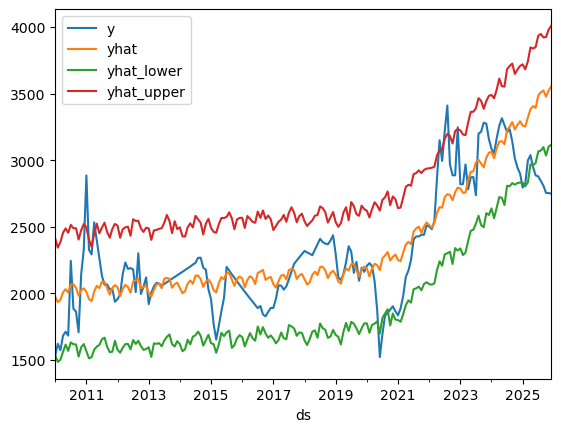

In [17]:
pd.concat([df_final.set_index('ds')['y'], forecast.set_index('ds')[['yhat', 'yhat_lower', 'yhat_upper']]], axis=1).plot()

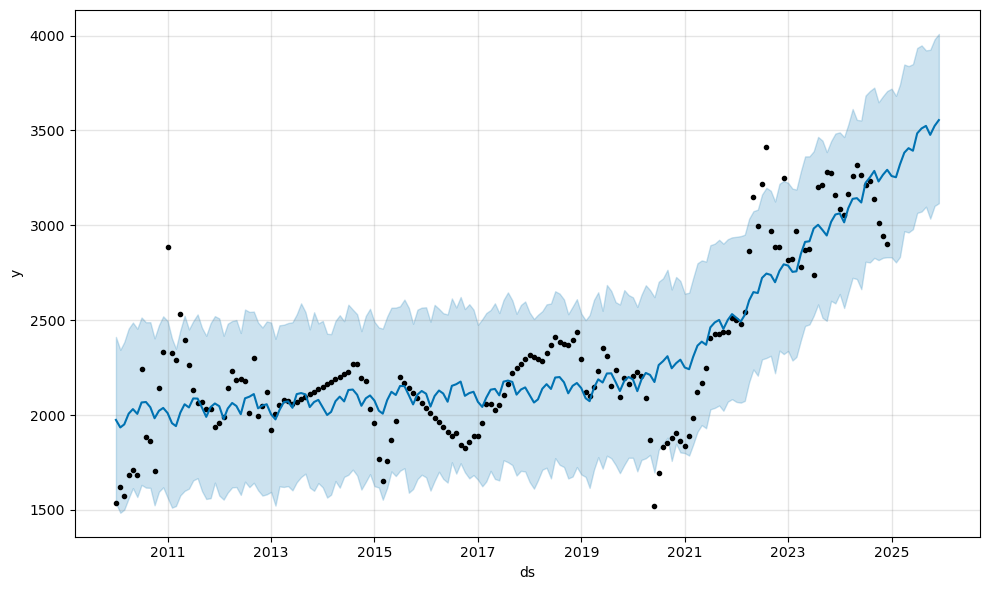

In [18]:
fig1=m.plot(forecast)

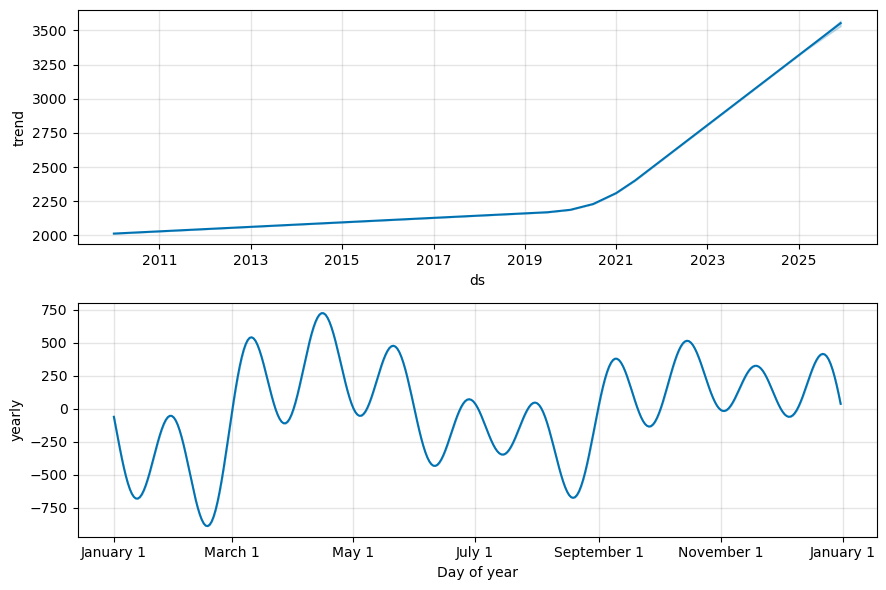

In [19]:
fig2=m.plot_components(forecast)

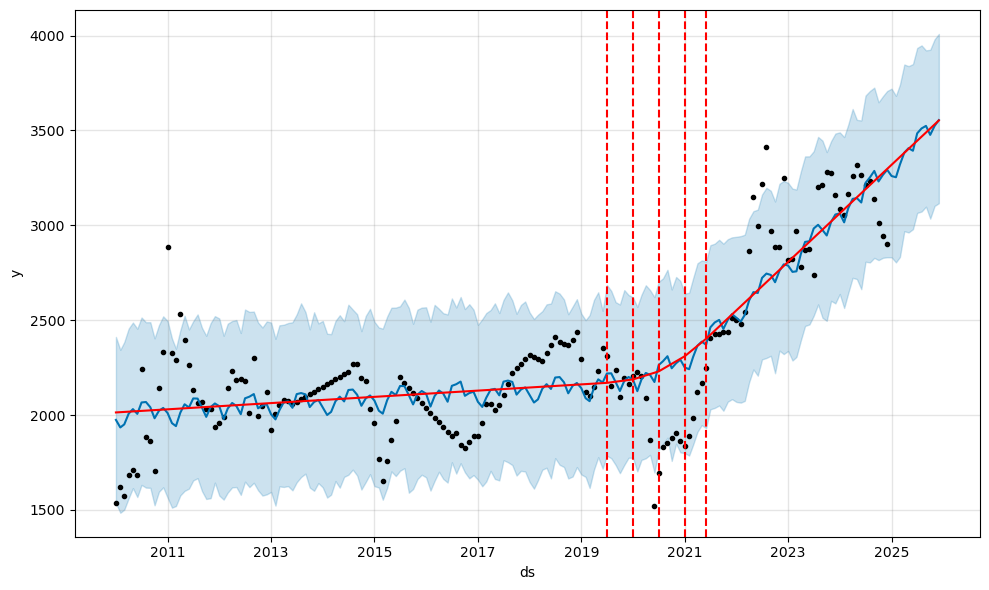

In [20]:
from prophet.plot import add_changepoints_to_plot
fig= m.plot(forecast)
a=add_changepoints_to_plot(fig.gca(), m, forecast)


In [21]:
deltas=m.params['delta'].mean(0)
deltas

array([-7.46013e-09,  1.47064e-09,  4.85345e-10, -1.04791e-09,
       -1.54304e-08, -4.06342e-09, -7.33513e-09, -9.54270e-09,
       -4.43546e-09, -3.65303e-10,  1.94716e-06,  7.16035e-08,
        8.44343e-06,  3.74904e-05,  1.92536e-05,  1.28196e-06,
       -3.80455e-09, -1.62374e-10,  2.78346e-08,  8.36320e-02,
        2.16116e-01,  3.22082e-01,  2.81045e-01,  1.43482e-01,
       -2.40312e-09])

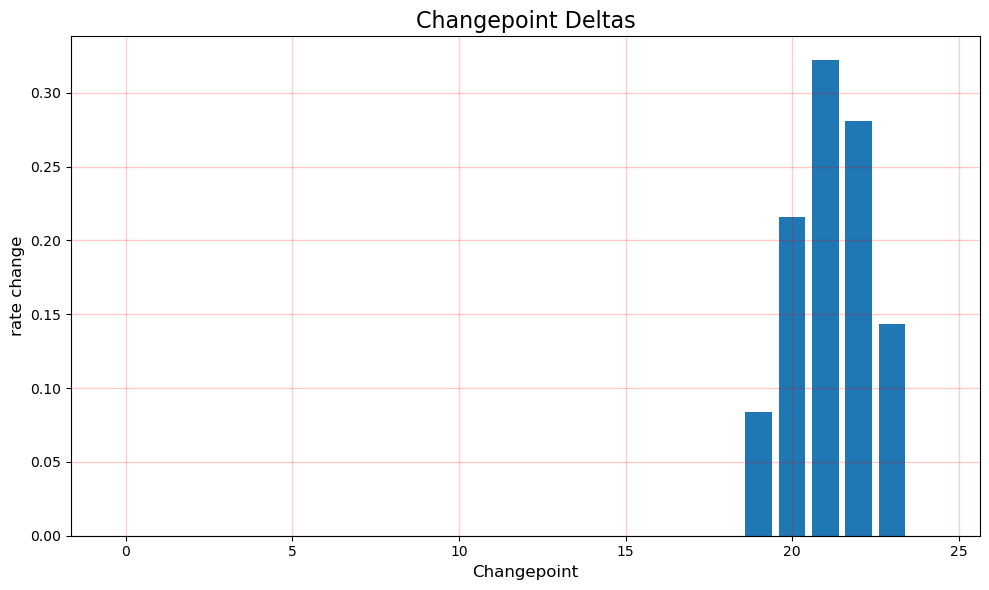

In [22]:
fig = plt.figure(facecolor='w', figsize=(10, 6))
ax = fig.add_subplot(111)
ax.bar(range(len(deltas)), deltas)
ax.grid(True, which='major', c='red', ls='-', lw=1, alpha=0.2)
ax.set_title('Changepoint Deltas', fontsize=16)
ax.set_xlabel('Changepoint', fontsize=12)
ax.set_ylabel('rate change', fontsize=12)
fig.tight_layout()

In [23]:
m.changepoints

6     2010-07-01
11    2010-12-01
17    2011-06-01
23    2011-12-01
29    2012-06-01
34    2012-11-01
40    2013-05-01
46    2013-11-01
51    2014-04-01
57    2014-10-01
63    2015-04-01
69    2015-10-01
74    2016-03-01
80    2016-09-01
86    2017-03-01
92    2017-09-01
97    2018-02-01
103   2018-08-01
109   2019-02-01
114   2019-07-01
120   2020-01-01
126   2020-07-01
132   2021-01-01
137   2021-06-01
143   2021-12-01
Name: ds, dtype: datetime64[ns]

12:27:02 - cmdstanpy - INFO - Chain [1] start processing
12:27:02 - cmdstanpy - INFO - Chain [1] done processing


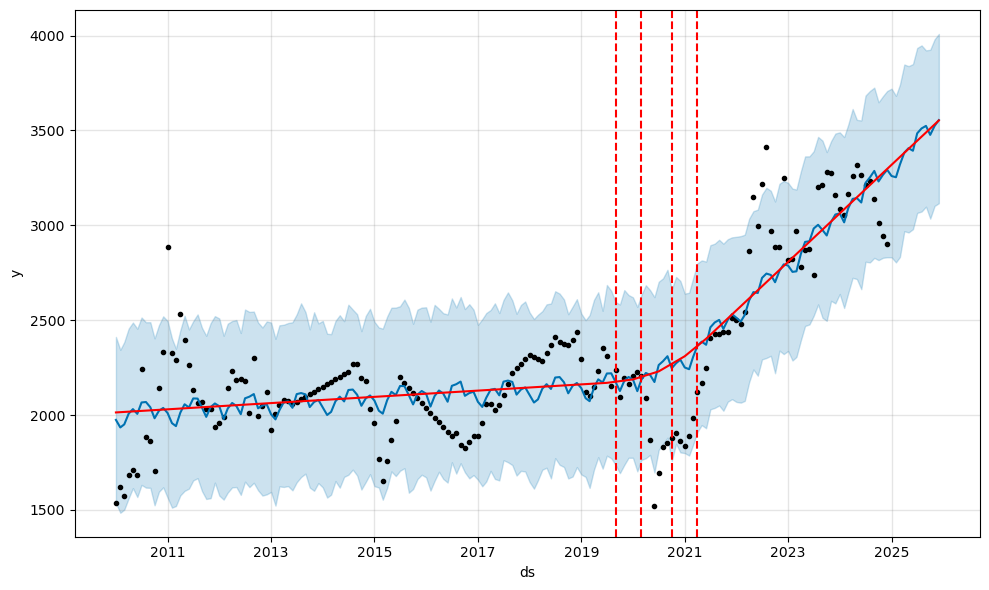

In [24]:
#increase the number of changepoints
pro_change=Prophet(changepoint_range=0.9, yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
forecast_change=pro_change.fit(train).predict(future)
fig= pro_change.plot(forecast);
a = add_changepoints_to_plot(fig.gca(), pro_change, forecast)


In [25]:
# visualize by sections
from prophet.plot import plot_plotly, plot_components_plotly
import plotly.offline as py

fig = plot_plotly(m, forecast)
py.iplot(fig)

In [26]:
#model measurement
from prophet.diagnostics import cross_validation, performance_metrics
cv_results = cross_validation(
    m,
    initial='730 days',    # ~24 months (2 years)
    period='180 days',     # ~6 months
    horizon='90 days',     # ~3 months
    parallel="processes"
)


In [27]:
cv_results.head()

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2012-06-01,1238.504094,1030.151967,1445.870073,2189.8439,2012-05-08
1,2012-07-01,3132.196701,2918.271685,3329.390081,2179.6979,2012-05-08
2,2012-08-01,2075.795391,1873.251104,2284.580929,2009.1007,2012-05-08
3,2012-12-01,2536.947986,2171.618201,2915.488571,2119.6854,2012-11-04
4,2013-01-01,2266.485220,1895.313884,2655.259379,1919.1007,2012-11-04


In [28]:
df_p = performance_metrics(cv_results)
df_p

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,8 days,35328.020310,187.957496,160.262618,0.080961,0.069301,0.076838,1.000000
1,10 days,33785.817592,183.809188,152.008873,0.077005,0.069301,0.073044,1.000000
2,12 days,31812.278344,178.359968,137.318495,0.070031,0.026766,0.066178,1.000000
3,13 days,46636.882949,215.955743,175.685351,0.085385,0.089014,0.082860,1.000000
4,14 days,44358.562119,210.614724,168.610457,0.082718,0.070348,0.080394,1.000000
5,15 days,107894.269522,328.472631,256.065588,0.112376,0.134246,0.114523,0.857143
6,18 days,112808.332239,335.869517,257.053032,0.101486,0.092022,0.108114,0.857143
7,19 days,113190.226171,336.437552,259.940077,0.103089,0.092022,0.109770,0.857143
8,20 days,113689.333837,337.178490,266.960172,0.105426,0.092022,0.112076,0.857143
9,23 days,119197.231590,345.249521,281.866302,0.105683,0.098364,0.112902,0.857143
